In [79]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import time   

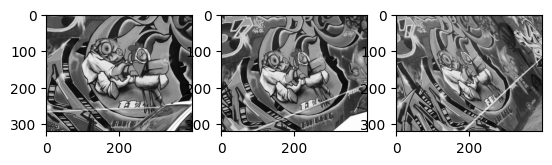

In [ ]:
from pathlib import Path

image_dir = next(
    (path for path in (Path("assignment1/data/graf"), Path("data/graf")) if path.is_dir()),
    None,
)
if image_dir is None:
    raise FileNotFoundError("Could not find data/graf relative to the workspace or assignment1 directory")

im1 = cv.imread(str(image_dir / "img1.ppm"), cv.IMREAD_GRAYSCALE)
im2 = cv.imread(str(image_dir / "img2.ppm"), cv.IMREAD_GRAYSCALE)
im3 = cv.imread(str(image_dir / "img4.ppm"), cv.IMREAD_GRAYSCALE)
if im1 is None or im2 is None or im3 is None:
    raise FileNotFoundError(f"Could not load img1.ppm, img2.ppm, and img4.ppm from {image_dir.resolve()}")

plt.subplot(1, 3, 1)
plt.imshow(im1, cmap='gray')
plt.subplot(1, 3, 2)
plt.imshow(im2, cmap='gray')
plt.subplot(1, 3, 3)
plt.imshow(im3, cmap='gray')
plt.show()



Time taken to compute SIFT features: 0.0352 seconds
Number of keypoints in image 1: 501
Number of keypoints in image 2: 501
Number of keypoints in image 3: 500


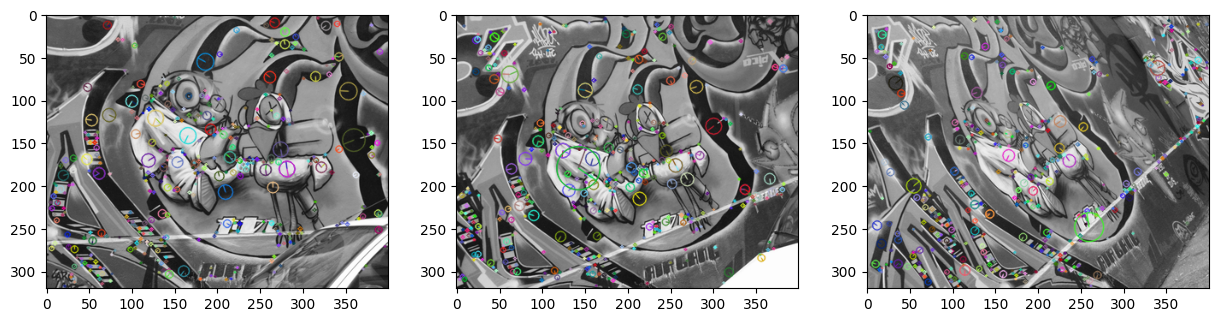

Time taken to compute FAST features: 0.0000 seconds
Number of keypoints in image 1 (FAST): 487
Number of keypoints in image 2 (FAST): 572
Number of keypoints in image 3 (FAST): 620


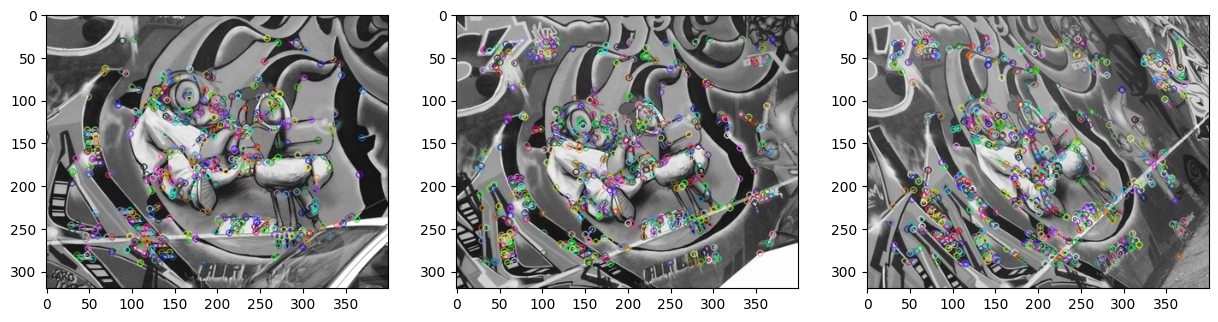

In [81]:
sift = cv.SIFT_create(nfeatures=500, nOctaveLayers=3, contrastThreshold=0.03, edgeThreshold=10, sigma=1.6)
start_time = time.time()
kp1, des1 = sift.detectAndCompute(im1, None)
kp2, des2 = sift.detectAndCompute(im2, None)
kp3, des3 = sift.detectAndCompute(im3, None)
end_time = time.time()
print(f"Time taken to compute SIFT features: {end_time - start_time:.4f} seconds")
print(f"Number of keypoints in image 1: {len(kp1)}")
print(f"Number of keypoints in image 2: {len(kp2)}")
print(f"Number of keypoints in image 3: {len(kp3)}")

image_with_keypoints1 = cv.drawKeypoints(im1, kp1, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
image_with_keypoints2 = cv.drawKeypoints(im2, kp2, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
image_with_keypoints3 = cv.drawKeypoints(im3, kp3, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(image_with_keypoints1, cmap='gray')
plt.subplot(1, 3, 2)
plt.imshow(image_with_keypoints2, cmap='gray')
plt.subplot(1, 3, 3)
plt.imshow(image_with_keypoints3, cmap='gray')
plt.show()


fast = cv.FastFeatureDetector_create(threshold=50, nonmaxSuppression=True)
start_time = time.time()
kp1_fast = fast.detect(im1, None)
kp2_fast = fast.detect(im2, None)
kp3_fast = fast.detect(im3, None)

brief = cv.xfeatures2d.BriefDescriptorExtractor_create()
kp1_fast, des1_fast = brief.compute(im1, kp1_fast)
kp2_fast, des2_fast = brief.compute(im2, kp2_fast)
kp3_fast, des3_fast = brief.compute(im3, kp3_fast)
end_time = time.time()
print(f"Time taken to compute FAST features: {end_time - start_time:.4f} seconds")
print(f"Number of keypoints in image 1 (FAST): {len(kp1_fast)}")
print(f"Number of keypoints in image 2 (FAST): {len(kp2_fast)}")
print(f"Number of keypoints in image 3 (FAST): {len(kp3_fast)}")

image_with_keypoints1_fast = cv.drawKeypoints(im1, kp1_fast, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
image_with_keypoints2_fast = cv.drawKeypoints(im2, kp2_fast, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
image_with_keypoints3_fast = cv.drawKeypoints(im3, kp3_fast, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(image_with_keypoints1_fast, cmap='gray')
plt.subplot(1, 3, 2)
plt.imshow(image_with_keypoints2_fast, cmap='gray')
plt.subplot(1, 3, 3)
plt.imshow(image_with_keypoints3_fast, cmap='gray')
plt.show()  


# 2.2 e 2.4
## SIFT e Fast


Time taken to match and verify SIFT features: 0.0025 seconds
SIFT mutual ratio-test matches: 220; geometrically correct: 219
SIFT precision: 99.55%
Mean reprojection error: 0.78 px
Median reprojection error: 0.29 px
Number of SIFT matches drawn: 20


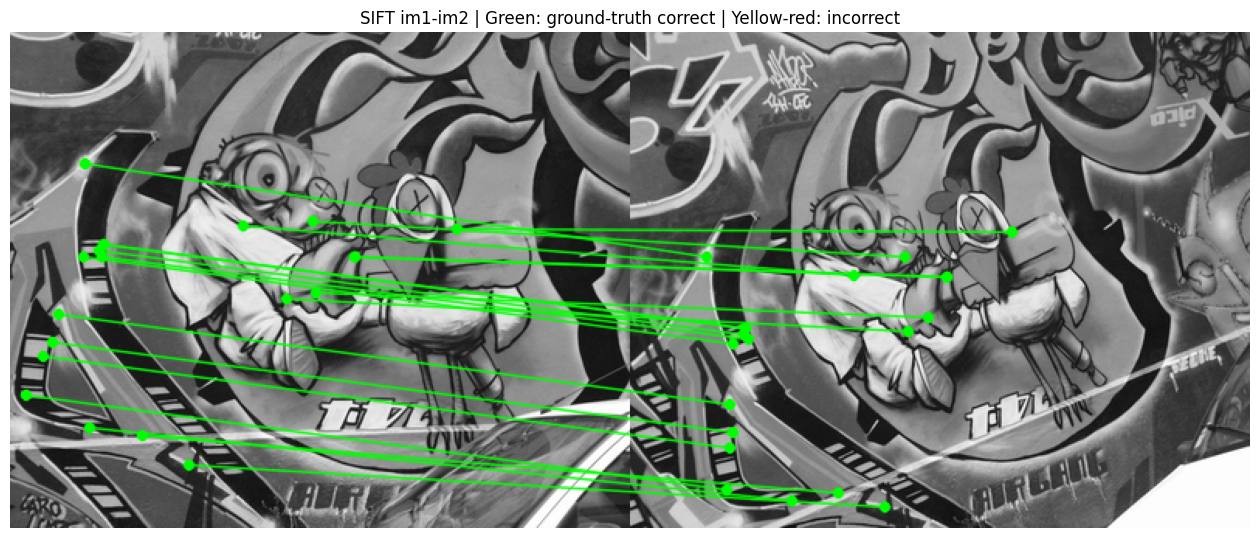

Time taken to match and verify SIFT features: 0.0037 seconds
SIFT mutual ratio-test matches: 16; geometrically correct: 11
SIFT precision: 68.75%
Mean reprojection error: 29.36 px
Median reprojection error: 2.73 px
Number of SIFT matches drawn: 16


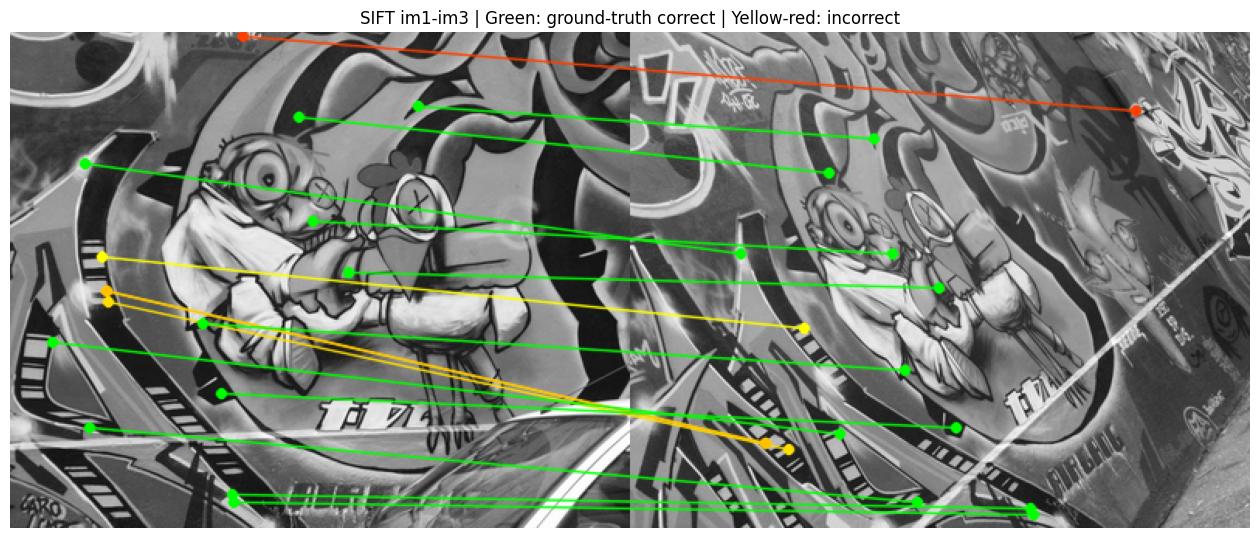

Time taken to match and verify FAST features: 0.0027 seconds
FAST mutual matches: 11; geometrically correct: 11
FAST precision: 100.00%
Mean reprojection error: 0.76 px
Median reprojection error: 0.71 px
Number of FAST matches drawn: 11


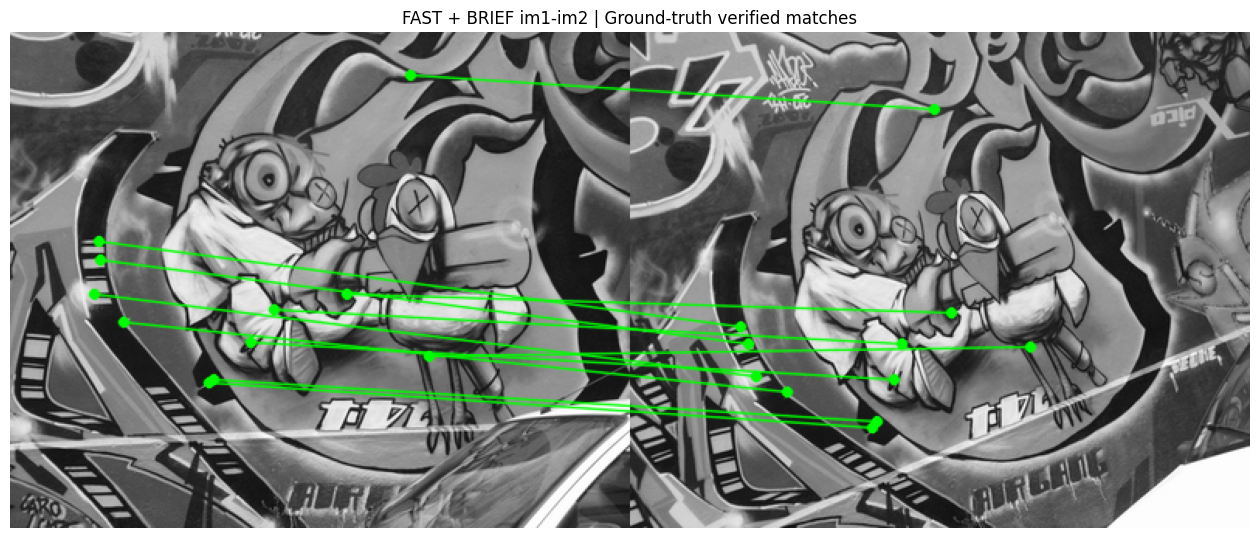

No reliable FAST matches found between im1 and im3.


In [82]:
# Ground-truth homographies
H1_2 = np.loadtxt("data/graf/H1to2p.txt").astype(np.float32)
H1_3 = np.loadtxt("data/graf/H1to4p.txt").astype(np.float32)

reprojection_threshold = 5.0
ratio_threshold = 0.75


# ============================================================
# SIFT [im1 - im2]
# ============================================================

matcher = cv.BFMatcher(cv.NORM_L2)

start_time = time.time()

forward1_2 = matcher.knnMatch(des1, des2, k=2)
reverse1_2 = matcher.knnMatch(des2, des1, k=2)

forward_good1_2 = {
    m.queryIdx: m for pair in forward1_2 if len(pair) == 2
    for m, n in [pair] if m.distance < ratio_threshold * n.distance
}

reverse_good1_2 = {
    m.queryIdx: m for pair in reverse1_2 if len(pair) == 2
    for m, n in [pair] if m.distance < ratio_threshold * n.distance
}

matches1_2 = [
    match for match in forward_good1_2.values()
    if match.trainIdx in reverse_good1_2
    and reverse_good1_2[match.trainIdx].trainIdx == match.queryIdx
]

matches1_2.sort(key=lambda match: match.distance)

if len(matches1_2) == 0:
    print("No reliable SIFT matches found between im1 and im2.")

else:
    points1 = np.float32([kp1[m.queryIdx].pt for m in matches1_2]).reshape(-1, 1, 2)
    points2 = np.float32([kp2[m.trainIdx].pt for m in matches1_2]).reshape(-1, 1, 2)

    projected_points2 = cv.perspectiveTransform(points1, H1_2)

    errors1_2 = np.linalg.norm(
        projected_points2.reshape(-1, 2) - points2.reshape(-1, 2),
        axis=1
    )

    inliers1_2 = errors1_2 < reprojection_threshold

    end_time = time.time()

    print(f"Time taken to match and verify SIFT features: {end_time - start_time:.4f} seconds")
    print(f"SIFT mutual ratio-test matches: {len(matches1_2)}; geometrically correct: {int(inliers1_2.sum())}")
    print(f"SIFT precision: {inliers1_2.sum() / len(matches1_2):.2%}")
    print(f"Mean reprojection error: {np.mean(errors1_2):.2f} px")
    print(f"Median reprojection error: {np.median(errors1_2):.2f} px")

    max_matches = 20
    matches_to_draw = matches1_2[:max_matches]
    draw_inliers = inliers1_2[:max_matches]

    distances = np.array([match.distance for match in matches_to_draw], dtype=np.float32)
    distance_span = float(np.ptp(distances)) if len(distances) else 0.0

    height = max(im1.shape[0], im2.shape[0])
    width1 = im1.shape[1]

    image_matches = np.zeros((height, width1 + im2.shape[1], 3), dtype=np.uint8)

    image_matches[:im1.shape[0], :width1] = cv.cvtColor(im1, cv.COLOR_GRAY2BGR)
    image_matches[:im2.shape[0], width1:] = cv.cvtColor(im2, cv.COLOR_GRAY2BGR)

    for index, match in enumerate(matches_to_draw):
        point1 = tuple(np.round(kp1[match.queryIdx].pt).astype(int))
        point2 = tuple(np.round(kp2[match.trainIdx].pt).astype(int) + np.array([width1, 0]))

        if draw_inliers[index]:
            color = (0, 255, 0)
        else:
            relative_distance = (match.distance - distances.min()) / distance_span if distance_span else 0.0
            color = (0, int(255 * (1 - relative_distance)), 255)

        cv.line(image_matches, point1, point2, color, 1, cv.LINE_AA)
        cv.circle(image_matches, point1, 3, color, -1, cv.LINE_AA)
        cv.circle(image_matches, point2, 3, color, -1, cv.LINE_AA)

    print(f"Number of SIFT matches drawn: {len(matches_to_draw)}")

    plt.figure(figsize=(16, 8))
    plt.imshow(cv.cvtColor(image_matches, cv.COLOR_BGR2RGB))
    plt.title("SIFT im1-im2 | Green: ground-truth correct | Yellow-red: incorrect")
    plt.axis("off")
    plt.show()


# ============================================================
# SIFT [im1 - im3]
# ============================================================

start_time = time.time()

forward1_3 = matcher.knnMatch(des1, des3, k=2)
reverse1_3 = matcher.knnMatch(des3, des1, k=2)

forward_good1_3 = {
    m.queryIdx: m for pair in forward1_3 if len(pair) == 2
    for m, n in [pair] if m.distance < ratio_threshold * n.distance
}

reverse_good1_3 = {
    m.queryIdx: m for pair in reverse1_3 if len(pair) == 2
    for m, n in [pair] if m.distance < ratio_threshold * n.distance
}

matches1_3 = [
    match for match in forward_good1_3.values()
    if match.trainIdx in reverse_good1_3
    and reverse_good1_3[match.trainIdx].trainIdx == match.queryIdx
]

matches1_3.sort(key=lambda match: match.distance)

if len(matches1_3) == 0:
    print("No reliable SIFT matches found between im1 and im3.")

else:
    points1 = np.float32([kp1[m.queryIdx].pt for m in matches1_3]).reshape(-1, 1, 2)
    points3 = np.float32([kp3[m.trainIdx].pt for m in matches1_3]).reshape(-1, 1, 2)

    projected_points3 = cv.perspectiveTransform(points1, H1_3)

    errors1_3 = np.linalg.norm(
        projected_points3.reshape(-1, 2) - points3.reshape(-1, 2),
        axis=1
    )

    inliers1_3 = errors1_3 < reprojection_threshold

    end_time = time.time()

    print(f"Time taken to match and verify SIFT features: {end_time - start_time:.4f} seconds")
    print(f"SIFT mutual ratio-test matches: {len(matches1_3)}; geometrically correct: {int(inliers1_3.sum())}")
    print(f"SIFT precision: {inliers1_3.sum() / len(matches1_3):.2%}")
    print(f"Mean reprojection error: {np.mean(errors1_3):.2f} px")
    print(f"Median reprojection error: {np.median(errors1_3):.2f} px")

    max_matches = 20
    matches_to_draw = matches1_3[:max_matches]
    draw_inliers = inliers1_3[:max_matches]

    distances = np.array([match.distance for match in matches_to_draw], dtype=np.float32)
    distance_span = float(np.ptp(distances)) if len(distances) else 0.0

    height = max(im1.shape[0], im3.shape[0])
    width1 = im1.shape[1]

    image_matches = np.zeros((height, width1 + im3.shape[1], 3), dtype=np.uint8)

    image_matches[:im1.shape[0], :width1] = cv.cvtColor(im1, cv.COLOR_GRAY2BGR)
    image_matches[:im3.shape[0], width1:] = cv.cvtColor(im3, cv.COLOR_GRAY2BGR)

    for index, match in enumerate(matches_to_draw):
        point1 = tuple(np.round(kp1[match.queryIdx].pt).astype(int))
        point3 = tuple(np.round(kp3[match.trainIdx].pt).astype(int) + np.array([width1, 0]))

        if draw_inliers[index]:
            color = (0, 255, 0)
        else:
            relative_distance = (match.distance - distances.min()) / distance_span if distance_span else 0.0
            color = (0, int(255 * (1 - relative_distance)), 255)

        cv.line(image_matches, point1, point3, color, 1, cv.LINE_AA)
        cv.circle(image_matches, point1, 3, color, -1, cv.LINE_AA)
        cv.circle(image_matches, point3, 3, color, -1, cv.LINE_AA)

    print(f"Number of SIFT matches drawn: {len(matches_to_draw)}")

    plt.figure(figsize=(16, 8))
    plt.imshow(cv.cvtColor(image_matches, cv.COLOR_BGR2RGB))
    plt.title("SIFT im1-im3 | Green: ground-truth correct | Yellow-red: incorrect")
    plt.axis("off")
    plt.show()


# ============================================================
# FAST + BRIEF [im1 - im2]
# ============================================================

bf = cv.BFMatcher(cv.NORM_HAMMING)

start_time = time.time()

matches_fast1_2 = bf.knnMatch(des1_fast, des2_fast, k=2)

good_matches_fast1_2 = []

for pair in matches_fast1_2:
    if len(pair) == 2:
        m, n = pair

        if m.distance < ratio_threshold * n.distance:
            good_matches_fast1_2.append(m)

rev_matches_fast1_2 = bf.knnMatch(des2_fast, des1_fast, k=2)

good_rev_matches_fast1_2 = []

for pair in rev_matches_fast1_2:
    if len(pair) == 2:
        m, n = pair

        if m.distance < ratio_threshold * n.distance:
            good_rev_matches_fast1_2.append(m)

reverse_good_fast1_2 = {m.queryIdx: m for m in good_rev_matches_fast1_2}

mutual_matches_fast1_2 = [
    match for match in good_matches_fast1_2
    if match.trainIdx in reverse_good_fast1_2
    and reverse_good_fast1_2[match.trainIdx].trainIdx == match.queryIdx
]

mutual_matches_fast1_2.sort(key=lambda match: match.distance)

if len(mutual_matches_fast1_2) == 0:
    print("No reliable FAST matches found between im1 and im2.")

else:
    pts1_fast = np.float32([kp1_fast[m.queryIdx].pt for m in mutual_matches_fast1_2]).reshape(-1, 1, 2)
    pts2_fast = np.float32([kp2_fast[m.trainIdx].pt for m in mutual_matches_fast1_2]).reshape(-1, 1, 2)

    projected_pts2_fast = cv.perspectiveTransform(pts1_fast, H1_2)

    errors_fast1_2 = np.linalg.norm(
        projected_pts2_fast.reshape(-1, 2) - pts2_fast.reshape(-1, 2),
        axis=1
    )

    inliers_fast1_2 = errors_fast1_2 < reprojection_threshold

    end_time = time.time()

    print(f"Time taken to match and verify FAST features: {end_time - start_time:.4f} seconds")
    print(f"FAST mutual matches: {len(mutual_matches_fast1_2)}; geometrically correct: {int(inliers_fast1_2.sum())}")
    print(f"FAST precision: {inliers_fast1_2.sum() / len(mutual_matches_fast1_2):.2%}")
    print(f"Mean reprojection error: {np.mean(errors_fast1_2):.2f} px")
    print(f"Median reprojection error: {np.median(errors_fast1_2):.2f} px")

    verified_matches_fast1_2 = [
        m for m, keep in zip(mutual_matches_fast1_2, inliers_fast1_2)
        if keep
    ]

    max_matches_fast = 20
    matches_to_draw_fast = verified_matches_fast1_2[:max_matches_fast]

    height_fast = max(im1.shape[0], im2.shape[0])
    width1_fast = im1.shape[1]

    image_matches_fast = np.zeros(
        (height_fast, width1_fast + im2.shape[1], 3),
        dtype=np.uint8
    )

    image_matches_fast[:im1.shape[0], :width1_fast] = cv.cvtColor(im1, cv.COLOR_GRAY2BGR)
    image_matches_fast[:im2.shape[0], width1_fast:] = cv.cvtColor(im2, cv.COLOR_GRAY2BGR)

    for match in matches_to_draw_fast:
        pt1 = tuple(np.round(kp1_fast[match.queryIdx].pt).astype(int))
        pt2 = tuple(np.round(kp2_fast[match.trainIdx].pt).astype(int) + np.array([width1_fast, 0]))

        cv.line(image_matches_fast, pt1, pt2, (0, 255, 0), 1, cv.LINE_AA)
        cv.circle(image_matches_fast, pt1, 3, (0, 255, 0), -1, cv.LINE_AA)
        cv.circle(image_matches_fast, pt2, 3, (0, 255, 0), -1, cv.LINE_AA)

    print(f"Number of FAST matches drawn: {len(matches_to_draw_fast)}")

    plt.figure(figsize=(16, 8))
    plt.imshow(cv.cvtColor(image_matches_fast, cv.COLOR_BGR2RGB))
    plt.title("FAST + BRIEF im1-im2 | Ground-truth verified matches")
    plt.axis("off")
    plt.show()


# ============================================================
# FAST + BRIEF [im1 - im3]
# ============================================================

start_time = time.time()

matches_fast1_3 = bf.knnMatch(des1_fast, des3_fast, k=2)

good_matches_fast1_3 = []

for pair in matches_fast1_3:
    if len(pair) == 2:
        m, n = pair

        if m.distance < ratio_threshold * n.distance:
            good_matches_fast1_3.append(m)

rev_matches_fast1_3 = bf.knnMatch(des3_fast, des1_fast, k=2)

good_rev_matches_fast1_3 = []

for pair in rev_matches_fast1_3:
    if len(pair) == 2:
        m, n = pair

        if m.distance < ratio_threshold * n.distance:
            good_rev_matches_fast1_3.append(m)

reverse_good_fast1_3 = {m.queryIdx: m for m in good_rev_matches_fast1_3}

mutual_matches_fast1_3 = [
    match for match in good_matches_fast1_3
    if match.trainIdx in reverse_good_fast1_3
    and reverse_good_fast1_3[match.trainIdx].trainIdx == match.queryIdx
]

mutual_matches_fast1_3.sort(key=lambda match: match.distance)

if len(mutual_matches_fast1_3) == 0:
    print("No reliable FAST matches found between im1 and im3.")

else:
    pts1_fast = np.float32([kp1_fast[m.queryIdx].pt for m in mutual_matches_fast1_3]).reshape(-1, 1, 2)
    pts3_fast = np.float32([kp3_fast[m.trainIdx].pt for m in mutual_matches_fast1_3]).reshape(-1, 1, 2)

    projected_pts3_fast = cv.perspectiveTransform(pts1_fast, H1_3)

    errors_fast1_3 = np.linalg.norm(
        projected_pts3_fast.reshape(-1, 2) - pts3_fast.reshape(-1, 2),
        axis=1
    )

    inliers_fast1_3 = errors_fast1_3 < reprojection_threshold

    end_time = time.time()

    print(f"Time taken to match and verify FAST features: {end_time - start_time:.4f} seconds")
    print(f"FAST mutual matches: {len(mutual_matches_fast1_3)}; geometrically correct: {int(inliers_fast1_3.sum())}")
    print(f"FAST precision: {inliers_fast1_3.sum() / len(mutual_matches_fast1_3):.2%}")
    print(f"Mean reprojection error: {np.mean(errors_fast1_3):.2f} px")
    print(f"Median reprojection error: {np.median(errors_fast1_3):.2f} px")

    verified_matches_fast1_3 = [
        m for m, keep in zip(mutual_matches_fast1_3, inliers_fast1_3)
        if keep
    ]

    max_matches_fast = 20
    matches_to_draw_fast = verified_matches_fast1_3[:max_matches_fast]

    height_fast = max(im1.shape[0], im3.shape[0])
    width1_fast = im1.shape[1]

    image_matches_fast = np.zeros(
        (height_fast, width1_fast + im3.shape[1], 3),
        dtype=np.uint8
    )

    image_matches_fast[:im1.shape[0], :width1_fast] = cv.cvtColor(im1, cv.COLOR_GRAY2BGR)
    image_matches_fast[:im3.shape[0], width1_fast:] = cv.cvtColor(im3, cv.COLOR_GRAY2BGR)

    for match in matches_to_draw_fast:
        pt1 = tuple(np.round(kp1_fast[match.queryIdx].pt).astype(int))
        pt3 = tuple(np.round(kp3_fast[match.trainIdx].pt).astype(int) + np.array([width1_fast, 0]))

        cv.line(image_matches_fast, pt1, pt3, (0, 255, 0), 1, cv.LINE_AA)
        cv.circle(image_matches_fast, pt1, 3, (0, 255, 0), -1, cv.LINE_AA)
        cv.circle(image_matches_fast, pt3, 3, (0, 255, 0), -1, cv.LINE_AA)

    print(f"Number of FAST matches drawn: {len(matches_to_draw_fast)}")

    plt.figure(figsize=(16, 8))
    plt.imshow(cv.cvtColor(image_matches_fast, cv.COLOR_BGR2RGB))
    plt.title("FAST + BRIEF im1-im3 | Ground-truth verified matches")
    plt.axis("off")
    plt.show()

# 2.4
## KAZE e ORB


Time taken to compute KAZE features: 0.1478 seconds
Number of keypoints in image 1 (KAZE): 1271
Number of keypoints in image 2 (KAZE): 1387
Number of keypoints in image 3 (KAZE): 1239


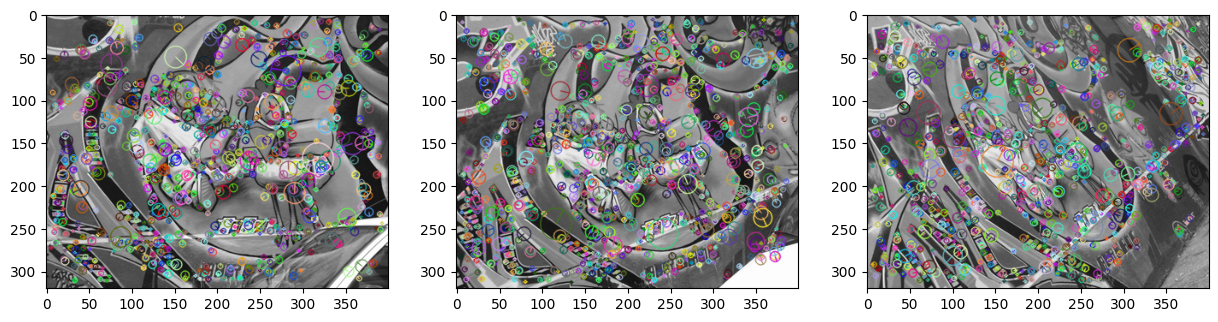

Time taken to compute ORB features: 0.0044 seconds
Number of keypoints in image 1 (ORB): 500
Number of keypoints in image 2 (ORB): 500
Number of keypoints in image 3 (ORB): 500


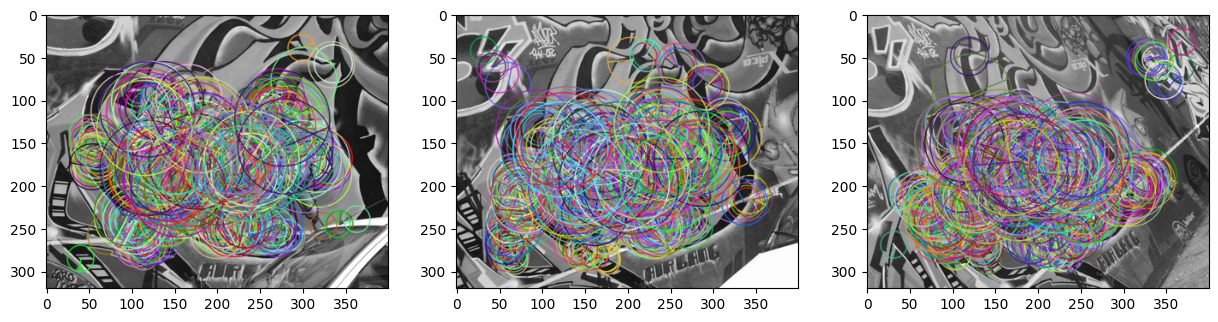

In [83]:
kaze = cv.KAZE_create()

start_time = time.time()
kp1_kaze, des1_kaze = kaze.detectAndCompute(im1, None)
kp2_kaze, des2_kaze = kaze.detectAndCompute(im2, None)
kp3_kaze, des3_kaze = kaze.detectAndCompute(im3, None)
end_time = time.time()
print(f"Time taken to compute KAZE features: {end_time - start_time:.4f} seconds")
print(f"Number of keypoints in image 1 (KAZE): {len(kp1_kaze)}")
print(f"Number of keypoints in image 2 (KAZE): {len(kp2_kaze)}")
print(f"Number of keypoints in image 3 (KAZE): {len(kp3_kaze)}")

image_kaze_keypoints1 = cv.drawKeypoints(im1, kp1_kaze, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
image_kaze_keypoints2 = cv.drawKeypoints(im2, kp2_kaze, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
image_kaze_keypoints3 = cv.drawKeypoints(im3, kp3_kaze, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(image_kaze_keypoints1, cmap='gray')
plt.subplot(1, 3, 2)
plt.imshow(image_kaze_keypoints2, cmap='gray')
plt.subplot(1, 3, 3)
plt.imshow(image_kaze_keypoints3, cmap='gray')
plt.show()


Orb = cv.ORB_create(nfeatures=500, scaleFactor=1.2, nlevels=8, edgeThreshold=31, firstLevel=0, WTA_K=2, scoreType=cv.ORB_HARRIS_SCORE, patchSize=31, fastThreshold=20)

start_time = time.time()
kp1_orb, des1_orb = Orb.detectAndCompute(im1, None)
kp2_orb, des2_orb = Orb.detectAndCompute(im2, None)
kp3_orb, des3_orb = Orb.detectAndCompute(im3, None)
end_time = time.time()
print(f"Time taken to compute ORB features: {end_time - start_time:.4f} seconds")
print(f"Number of keypoints in image 1 (ORB): {len(kp1_orb)}")
print(f"Number of keypoints in image 2 (ORB): {len(kp2_orb)}")
print(f"Number of keypoints in image 3 (ORB): {len(kp3_orb)}")

image_orb_keypoints1 = cv.drawKeypoints(im1, kp1_orb, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
image_orb_keypoints2 = cv.drawKeypoints(im2, kp2_orb, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
image_orb_keypoints3 = cv.drawKeypoints(im3, kp3_orb, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)    
plt.imshow(image_orb_keypoints1, cmap='gray')
plt.subplot(1, 3, 2)
plt.imshow(image_orb_keypoints2, cmap='gray')
plt.subplot(1, 3, 3)
plt.imshow(image_orb_keypoints3, cmap='gray')
plt.show()



Time taken to match and verify KAZE features: 0.0070 seconds
KAZE mutual matches: 407; geometrically correct: 406
KAZE precision: 99.75%
Mean reprojection error: 1.70 px
Median reprojection error: 0.57 px
Number of KAZE matches drawn: 20


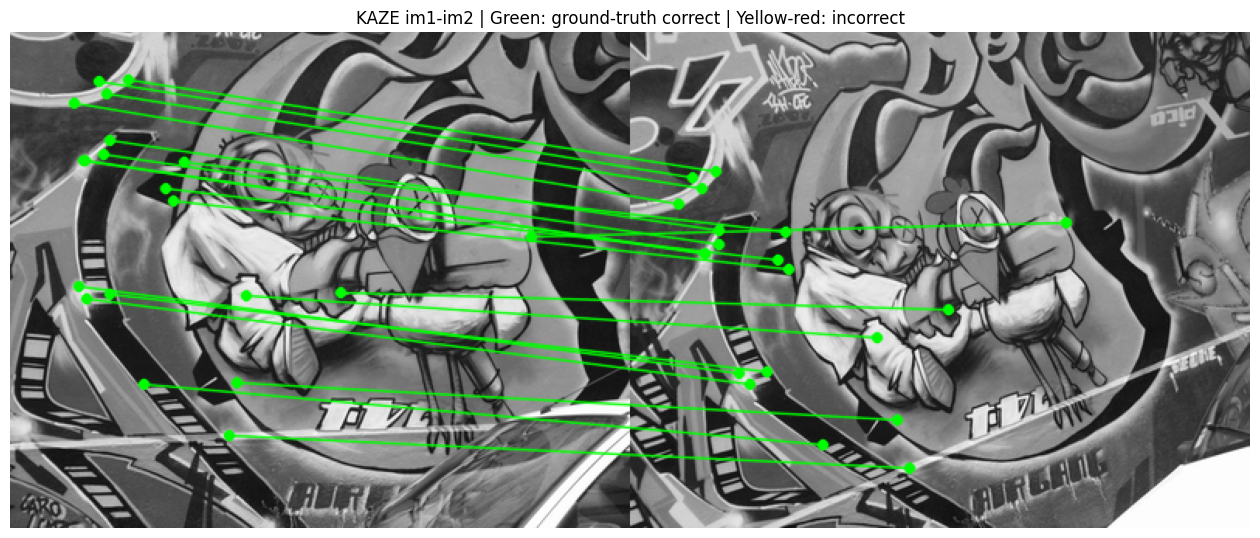

Time taken to match and verify KAZE features: 0.0072 seconds
KAZE mutual matches: 16; geometrically correct: 14
KAZE precision: 87.50%
Mean reprojection error: 31.92 px
Median reprojection error: 2.00 px
Number of KAZE matches drawn: 16


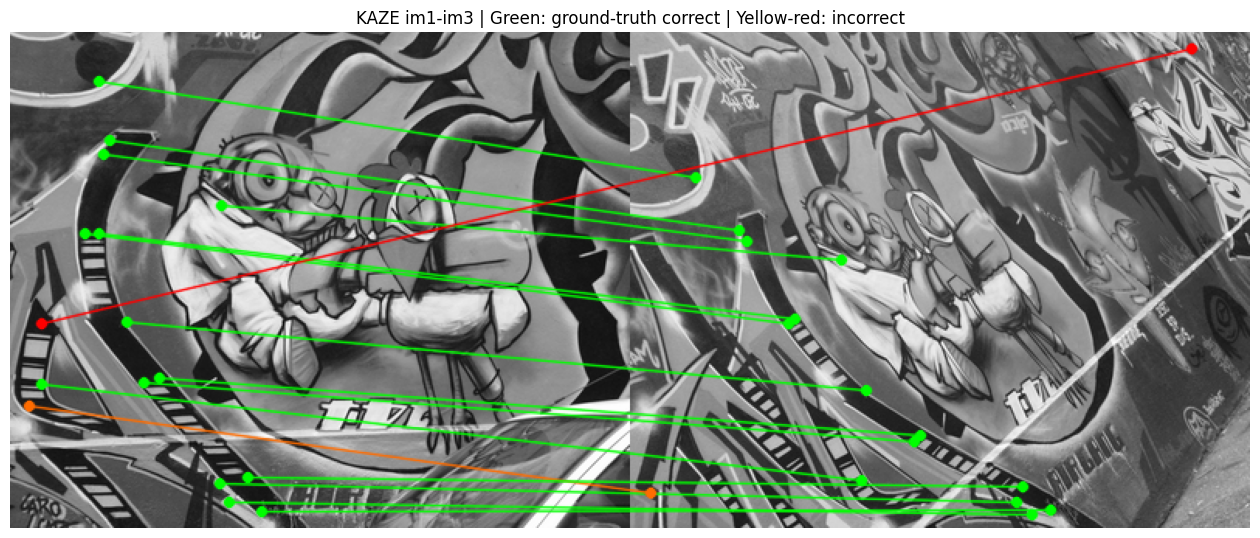

Time taken to match and verify ORB features: 0.0047 seconds
ORB mutual matches: 114; geometrically correct: 114
ORB precision: 100.00%
Mean reprojection error: 1.06 px
Median reprojection error: 0.89 px
Number of ORB matches drawn: 114


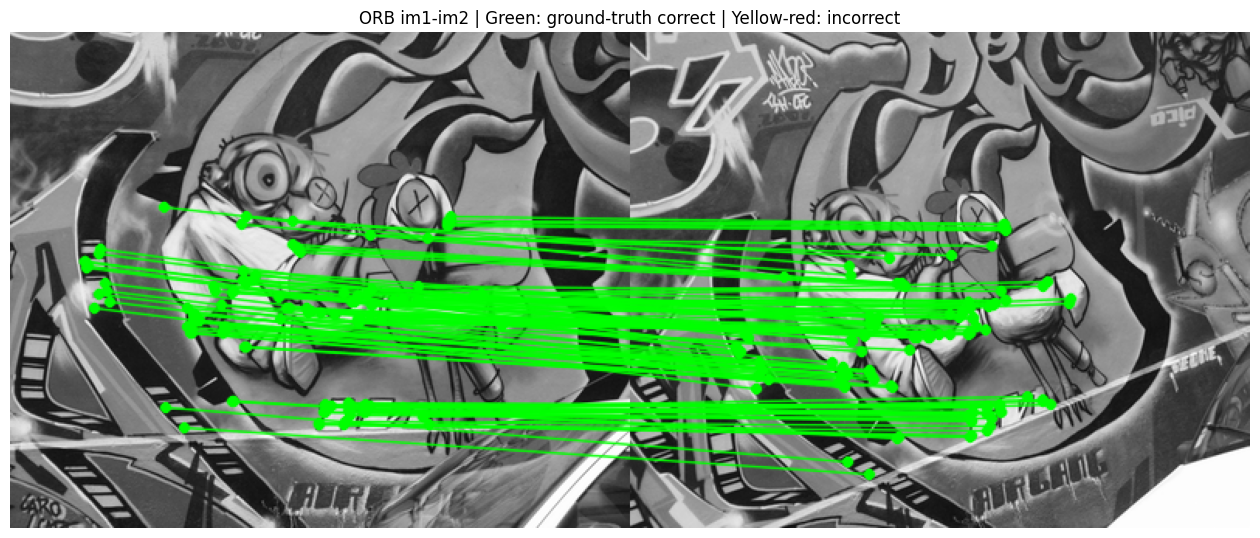

Time taken to match and verify ORB features: 0.0042 seconds
ORB mutual matches: 1; geometrically correct: 0
ORB precision: 0.00%
Mean reprojection error: 9.47 px
Median reprojection error: 9.47 px
Number of ORB matches drawn: 1


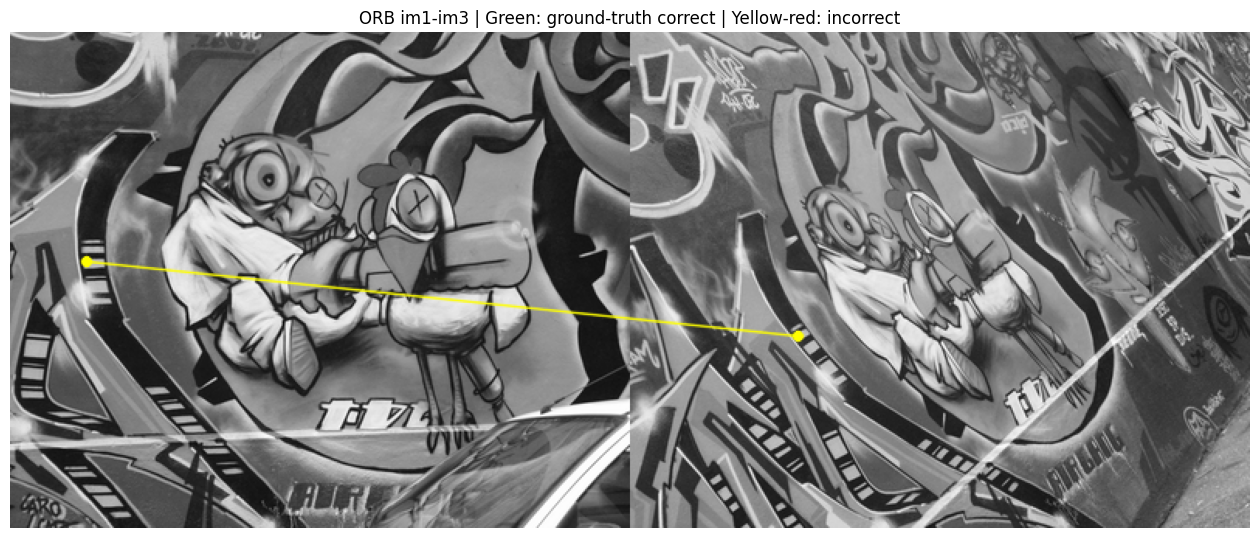

In [ ]:
# ============================================================
# KAZE [im1 - im2]
# ============================================================

bf_kaze = cv.BFMatcher(cv.NORM_L2)
ratio_threshold = 0.75

start_time = time.time()

matches_kaze1_2 = bf_kaze.knnMatch(des1_kaze, des2_kaze, k=2)

good_matches_kaze1_2 = []
for pair in matches_kaze1_2:
    if len(pair) == 2:
        m, n = pair
        if m.distance < ratio_threshold * n.distance:
            good_matches_kaze1_2.append(m)

rev_matches_kaze1_2 = bf_kaze.knnMatch(des2_kaze, des1_kaze, k=2)

good_rev_matches_kaze1_2 = []
for pair in rev_matches_kaze1_2:
    if len(pair) == 2:
        m, n = pair
        if m.distance < ratio_threshold * n.distance:
            good_rev_matches_kaze1_2.append(m)

reverse_good_kaze1_2 = {m.queryIdx: m for m in good_rev_matches_kaze1_2}

mutual_matches_kaze1_2 = [
    match for match in good_matches_kaze1_2
    if match.trainIdx in reverse_good_kaze1_2
    and reverse_good_kaze1_2[match.trainIdx].trainIdx == match.queryIdx
]

mutual_matches_kaze1_2.sort(key=lambda match: match.distance)

if len(mutual_matches_kaze1_2) == 0:
    print("No reliable KAZE matches found between im1 and im2.")

else:
    pts1_kaze = np.float32([kp1_kaze[m.queryIdx].pt for m in mutual_matches_kaze1_2]).reshape(-1, 1, 2)
    pts2_kaze = np.float32([kp2_kaze[m.trainIdx].pt for m in mutual_matches_kaze1_2]).reshape(-1, 1, 2)

    projected_pts2_kaze = cv.perspectiveTransform(pts1_kaze, H1_2)

    errors_kaze1_2 = np.linalg.norm(
        projected_pts2_kaze.reshape(-1, 2) - pts2_kaze.reshape(-1, 2),
        axis=1
    )

    inliers_kaze1_2 = errors_kaze1_2 < reprojection_threshold

    end_time = time.time()

    print(f"Time taken to match and verify KAZE features: {end_time - start_time:.4f} seconds")
    print(f"KAZE mutual matches: {len(mutual_matches_kaze1_2)}; geometrically correct: {int(inliers_kaze1_2.sum())}")
    print(f"KAZE precision: {inliers_kaze1_2.sum() / len(mutual_matches_kaze1_2):.2%}")
    print(f"Mean reprojection error: {np.mean(errors_kaze1_2):.2f} px")
    print(f"Median reprojection error: {np.median(errors_kaze1_2):.2f} px")

    max_matches_kaze = 20
    matches_to_draw_kaze = mutual_matches_kaze1_2[:max_matches_kaze]
    draw_inliers_kaze = inliers_kaze1_2[:max_matches_kaze]

    distances_kaze = np.array([match.distance for match in matches_to_draw_kaze], dtype=np.float32)
    distance_span_kaze = float(np.ptp(distances_kaze)) if len(distances_kaze) else 0.0

    height_kaze = max(im1.shape[0], im2.shape[0])
    width1_kaze = im1.shape[1]

    image_matches_kaze = np.zeros((height_kaze, width1_kaze + im2.shape[1], 3), dtype=np.uint8)
    image_matches_kaze[:im1.shape[0], :width1_kaze] = cv.cvtColor(im1, cv.COLOR_GRAY2BGR)
    image_matches_kaze[:im2.shape[0], width1_kaze:] = cv.cvtColor(im2, cv.COLOR_GRAY2BGR)

    for index, match in enumerate(matches_to_draw_kaze):
        point1 = tuple(np.round(kp1_kaze[match.queryIdx].pt).astype(int))
        point2 = tuple(np.round(kp2_kaze[match.trainIdx].pt).astype(int) + np.array([width1_kaze, 0]))

        if draw_inliers_kaze[index]:
            color = (0, 255, 0)
        else:
            relative_distance = (match.distance - distances_kaze.min()) / distance_span_kaze if distance_span_kaze else 0.0
            color = (0, int(255 * (1 - relative_distance)), 255)

        cv.line(image_matches_kaze, point1, point2, color, 1, cv.LINE_AA)
        cv.circle(image_matches_kaze, point1, 3, color, -1, cv.LINE_AA)
        cv.circle(image_matches_kaze, point2, 3, color, -1, cv.LINE_AA)

    print(f"Number of KAZE matches drawn: {len(matches_to_draw_kaze)}")

    plt.figure(figsize=(16, 8))
    plt.imshow(cv.cvtColor(image_matches_kaze, cv.COLOR_BGR2RGB))
    plt.title("KAZE im1-im2 | Green: ground-truth correct | Yellow-red: incorrect")
    plt.axis("off")
    plt.show()


# ============================================================
# KAZE [im1 - im3]
# ============================================================

start_time = time.time()

matches_kaze1_3 = bf_kaze.knnMatch(des1_kaze, des3_kaze, k=2)

good_matches_kaze1_3 = []
for pair in matches_kaze1_3:
    if len(pair) == 2:
        m, n = pair
        if m.distance < ratio_threshold * n.distance:
            good_matches_kaze1_3.append(m)

rev_matches_kaze1_3 = bf_kaze.knnMatch(des3_kaze, des1_kaze, k=2)

good_rev_matches_kaze1_3 = []
for pair in rev_matches_kaze1_3:
    if len(pair) == 2:
        m, n = pair
        if m.distance < ratio_threshold * n.distance:
            good_rev_matches_kaze1_3.append(m)

reverse_good_kaze1_3 = {m.queryIdx: m for m in good_rev_matches_kaze1_3}

mutual_matches_kaze1_3 = [
    match for match in good_matches_kaze1_3
    if match.trainIdx in reverse_good_kaze1_3
    and reverse_good_kaze1_3[match.trainIdx].trainIdx == match.queryIdx
]

mutual_matches_kaze1_3.sort(key=lambda match: match.distance)

if len(mutual_matches_kaze1_3) == 0:
    print("No reliable KAZE matches found between im1 and im3.")

else:
    pts1_kaze = np.float32([kp1_kaze[m.queryIdx].pt for m in mutual_matches_kaze1_3]).reshape(-1, 1, 2)
    pts3_kaze = np.float32([kp3_kaze[m.trainIdx].pt for m in mutual_matches_kaze1_3]).reshape(-1, 1, 2)

    projected_pts3_kaze = cv.perspectiveTransform(pts1_kaze, H1_3)

    errors_kaze1_3 = np.linalg.norm(
        projected_pts3_kaze.reshape(-1, 2) - pts3_kaze.reshape(-1, 2),
        axis=1
    )

    inliers_kaze1_3 = errors_kaze1_3 < reprojection_threshold

    end_time = time.time()

    print(f"Time taken to match and verify KAZE features: {end_time - start_time:.4f} seconds")
    print(f"KAZE mutual matches: {len(mutual_matches_kaze1_3)}; geometrically correct: {int(inliers_kaze1_3.sum())}")
    print(f"KAZE precision: {inliers_kaze1_3.sum() / len(mutual_matches_kaze1_3):.2%}")
    print(f"Mean reprojection error: {np.mean(errors_kaze1_3):.2f} px")
    print(f"Median reprojection error: {np.median(errors_kaze1_3):.2f} px")

    max_matches_kaze = 20
    matches_to_draw_kaze = mutual_matches_kaze1_3[:max_matches_kaze]
    draw_inliers_kaze = inliers_kaze1_3[:max_matches_kaze]

    distances_kaze = np.array([match.distance for match in matches_to_draw_kaze], dtype=np.float32)
    distance_span_kaze = float(np.ptp(distances_kaze)) if len(distances_kaze) else 0.0

    height_kaze = max(im1.shape[0], im3.shape[0])
    width1_kaze = im1.shape[1]

    image_matches_kaze = np.zeros((height_kaze, width1_kaze + im3.shape[1], 3), dtype=np.uint8)
    image_matches_kaze[:im1.shape[0], :width1_kaze] = cv.cvtColor(im1, cv.COLOR_GRAY2BGR)
    image_matches_kaze[:im3.shape[0], width1_kaze:] = cv.cvtColor(im3, cv.COLOR_GRAY2BGR)

    for index, match in enumerate(matches_to_draw_kaze):
        point1 = tuple(np.round(kp1_kaze[match.queryIdx].pt).astype(int))
        point3 = tuple(np.round(kp3_kaze[match.trainIdx].pt).astype(int) + np.array([width1_kaze, 0]))

        if draw_inliers_kaze[index]:
            color = (0, 255, 0)
        else:
            relative_distance = (match.distance - distances_kaze.min()) / distance_span_kaze if distance_span_kaze else 0.0
            color = (0, int(255 * (1 - relative_distance)), 255)

        cv.line(image_matches_kaze, point1, point3, color, 1, cv.LINE_AA)
        cv.circle(image_matches_kaze, point1, 3, color, -1, cv.LINE_AA)
        cv.circle(image_matches_kaze, point3, 3, color, -1, cv.LINE_AA)

    print(f"Number of KAZE matches drawn: {len(matches_to_draw_kaze)}")

    plt.figure(figsize=(16, 8))
    plt.imshow(cv.cvtColor(image_matches_kaze, cv.COLOR_BGR2RGB))
    plt.title("KAZE im1-im3 | Green: ground-truth correct | Yellow-red: incorrect")
    plt.axis("off")
    plt.show()


# ============================================================
# ORB [im1 - im2]
# ============================================================

bf_orb = cv.BFMatcher(cv.NORM_HAMMING)

start_time = time.time()

matches_orb1_2 = bf_orb.knnMatch(des1_orb, des2_orb, k=2)

good_matches_orb1_2 = []
for pair in matches_orb1_2:
    if len(pair) == 2:
        m, n = pair
        if m.distance < ratio_threshold * n.distance:
            good_matches_orb1_2.append(m)

rev_matches_orb1_2 = bf_orb.knnMatch(des2_orb, des1_orb, k=2)

good_rev_matches_orb1_2 = []
for pair in rev_matches_orb1_2:
    if len(pair) == 2:
        m, n = pair
        if m.distance < ratio_threshold * n.distance:
            good_rev_matches_orb1_2.append(m)

reverse_good_orb1_2 = {m.queryIdx: m for m in good_rev_matches_orb1_2}

mutual_matches_orb1_2 = [
    match for match in good_matches_orb1_2
    if match.trainIdx in reverse_good_orb1_2
    and reverse_good_orb1_2[match.trainIdx].trainIdx == match.queryIdx
]

mutual_matches_orb1_2.sort(key=lambda match: match.distance)

if len(mutual_matches_orb1_2) == 0:
    print("No reliable ORB matches found between im1 and im2.")

else:
    pts1_orb = np.float32([kp1_orb[m.queryIdx].pt for m in mutual_matches_orb1_2]).reshape(-1, 1, 2)
    pts2_orb = np.float32([kp2_orb[m.trainIdx].pt for m in mutual_matches_orb1_2]).reshape(-1, 1, 2)

    projected_pts2_orb = cv.perspectiveTransform(pts1_orb, H1_2)

    errors_orb1_2 = np.linalg.norm(
        projected_pts2_orb.reshape(-1, 2) - pts2_orb.reshape(-1, 2),
        axis=1
    )

    inliers_orb1_2 = errors_orb1_2 < reprojection_threshold

    end_time = time.time()

    print(f"Time taken to match and verify ORB features: {end_time - start_time:.4f} seconds")
    print(f"ORB mutual matches: {len(mutual_matches_orb1_2)}; geometrically correct: {int(inliers_orb1_2.sum())}")
    print(f"ORB precision: {inliers_orb1_2.sum() / len(mutual_matches_orb1_2):.2%}")
    print(f"Mean reprojection error: {np.mean(errors_orb1_2):.2f} px")
    print(f"Median reprojection error: {np.median(errors_orb1_2):.2f} px")

    max_matches_orb = 20
    matches_to_draw_orb = mutual_matches_orb1_2[:max_matches_orb]
    draw_inliers_orb = inliers_orb1_2[:max_matches_orb]

    distances_orb = np.array([match.distance for match in matches_to_draw_orb], dtype=np.float32)
    distance_span_orb = float(np.ptp(distances_orb)) if len(distances_orb) else 0.0

    height_orb = max(im1.shape[0], im2.shape[0])
    width1_orb = im1.shape[1]

    image_matches_orb = np.zeros((height_orb, width1_orb + im2.shape[1], 3), dtype=np.uint8)
    image_matches_orb[:im1.shape[0], :width1_orb] = cv.cvtColor(im1, cv.COLOR_GRAY2BGR)
    image_matches_orb[:im2.shape[0], width1_orb:] = cv.cvtColor(im2, cv.COLOR_GRAY2BGR)

    for index, match in enumerate(matches_to_draw_orb):
        point1 = tuple(np.round(kp1_orb[match.queryIdx].pt).astype(int))
        point2 = tuple(np.round(kp2_orb[match.trainIdx].pt).astype(int) + np.array([width1_orb, 0]))

        if draw_inliers_orb[index]:
            color = (0, 255, 0)
        else:
            relative_distance = (match.distance - distances_orb.min()) / distance_span_orb if distance_span_orb else 0.0
            color = (0, int(255 * (1 - relative_distance)), 255)

        cv.line(image_matches_orb, point1, point2, color, 1, cv.LINE_AA)
        cv.circle(image_matches_orb, point1, 3, color, -1, cv.LINE_AA)
        cv.circle(image_matches_orb, point2, 3, color, -1, cv.LINE_AA)

    print(f"Number of ORB matches drawn: {len(matches_to_draw_orb)}")

    plt.figure(figsize=(16, 8))
    plt.imshow(cv.cvtColor(image_matches_orb, cv.COLOR_BGR2RGB))
    plt.title("ORB im1-im2 | Green: ground-truth correct | Yellow-red: incorrect")
    plt.axis("off")
    plt.show()


# ============================================================
# ORB [im1 - im3]
# ============================================================

start_time = time.time()

matches_orb1_3 = bf_orb.knnMatch(des1_orb, des3_orb, k=2)

good_matches_orb1_3 = []
for pair in matches_orb1_3:
    if len(pair) == 2:
        m, n = pair
        if m.distance < ratio_threshold * n.distance:
            good_matches_orb1_3.append(m)

rev_matches_orb1_3 = bf_orb.knnMatch(des3_orb, des1_orb, k=2)

good_rev_matches_orb1_3 = []
for pair in rev_matches_orb1_3:
    if len(pair) == 2:
        m, n = pair
        if m.distance < ratio_threshold * n.distance:
            good_rev_matches_orb1_3.append(m)

reverse_good_orb1_3 = {m.queryIdx: m for m in good_rev_matches_orb1_3}

mutual_matches_orb1_3 = [
    match for match in good_matches_orb1_3
    if match.trainIdx in reverse_good_orb1_3
    and reverse_good_orb1_3[match.trainIdx].trainIdx == match.queryIdx
]

mutual_matches_orb1_3.sort(key=lambda match: match.distance)

if len(mutual_matches_orb1_3) == 0:
    print("No reliable ORB matches found between im1 and im3.")

else:
    pts1_orb = np.float32([kp1_orb[m.queryIdx].pt for m in mutual_matches_orb1_3]).reshape(-1, 1, 2)
    pts3_orb = np.float32([kp3_orb[m.trainIdx].pt for m in mutual_matches_orb1_3]).reshape(-1, 1, 2)

    projected_pts3_orb = cv.perspectiveTransform(pts1_orb, H1_3)

    errors_orb1_3 = np.linalg.norm(
        projected_pts3_orb.reshape(-1, 2) - pts3_orb.reshape(-1, 2),
        axis=1
    )

    inliers_orb1_3 = errors_orb1_3 < reprojection_threshold

    end_time = time.time()

    print(f"Time taken to match and verify ORB features: {end_time - start_time:.4f} seconds")
    print(f"ORB mutual matches: {len(mutual_matches_orb1_3)}; geometrically correct: {int(inliers_orb1_3.sum())}")
    print(f"ORB precision: {inliers_orb1_3.sum() / len(mutual_matches_orb1_3):.2%}")
    print(f"Mean reprojection error: {np.mean(errors_orb1_3):.2f} px")
    print(f"Median reprojection error: {np.median(errors_orb1_3):.2f} px")

    max_matches_orb = 20
    matches_to_draw_orb = mutual_matches_orb1_3[:max_matches_orb]
    draw_inliers_orb = inliers_orb1_3[:max_matches_orb]

    distances_orb = np.array([match.distance for match in matches_to_draw_orb], dtype=np.float32)
    distance_span_orb = float(np.ptp(distances_orb)) if len(distances_orb) else 0.0

    height_orb = max(im1.shape[0], im3.shape[0])
    width1_orb = im1.shape[1]

    image_matches_orb = np.zeros((height_orb, width1_orb + im3.shape[1], 3), dtype=np.uint8)
    image_matches_orb[:im1.shape[0], :width1_orb] = cv.cvtColor(im1, cv.COLOR_GRAY2BGR)
    image_matches_orb[:im3.shape[0], width1_orb:] = cv.cvtColor(im3, cv.COLOR_GRAY2BGR)

    for index, match in enumerate(matches_to_draw_orb):
        point1 = tuple(np.round(kp1_orb[match.queryIdx].pt).astype(int))
        point3 = tuple(np.round(kp3_orb[match.trainIdx].pt).astype(int) + np.array([width1_orb, 0]))

        if draw_inliers_orb[index]:
            color = (0, 255, 0)
        else:
            relative_distance = (match.distance - distances_orb.min()) / distance_span_orb if distance_span_orb else 0.0
            color = (0, int(255 * (1 - relative_distance)), 255)

        cv.line(image_matches_orb, point1, point3, color, 1, cv.LINE_AA)
        cv.circle(image_matches_orb, point1, 3, color, -1, cv.LINE_AA)
        cv.circle(image_matches_orb, point3, 3, color, -1, cv.LINE_AA)

    print(f"Number of ORB matches drawn: {len(matches_to_draw_orb)}")

    plt.figure(figsize=(16, 8))
    plt.imshow(cv.cvtColor(image_matches_orb, cv.COLOR_BGR2RGB))
    plt.title("ORB im1-im3 | Green: ground-truth correct | Yellow-red: incorrect")
    plt.axis("off")
    plt.show()